# Búsqueda, configuración final y registro de corridas

Este capítulo documenta lo que se entrenó y con qué configuración: la búsqueda de la tasa de aprendizaje (preregistro §4), cómo se aplicó la regla de selección, el hardware y el software de cada corrida, el costo, el conteo de todo lo examinado (enunciado §9.3) y las desviaciones respecto al preregistro. Todo sale de `results/e2/busqueda.csv`, `results/e2/corridas.csv` y los `resumen.json` de cada corrida.

In [1]:
import json, glob
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.width", 170)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
b = pd.read_csv(ROOT / "results/e2/busqueda.csv")
c = pd.read_csv(ROOT / "results/e2/corridas.csv")
res = {Path(p).parent.name: json.load(open(p)) for p in glob.glob(str(ROOT / "results/e2/corridas/*/resumen.json"))}
ORDEN = ["maskrcnn","htc","cascade","msrcnn","pointrend","yolov7","condinst","yolo26","yolov8","mask2former","yolo11","yolov9","solov2","clasico"]

## 3.2.1 Búsqueda de la tasa de aprendizaje

Para cada modelo se probaron **3 configuraciones**: la tasa por defecto de su marco multiplicada por 0.5, 1 y 2 (para el baseline clásico, la regularización λ en 1e-4, 1e-3 y 1e-2). Cada una se entrenó con la semilla 42 durante ⌈6/3⌉ = 2 épocas y se eligió por el F1 de instancia promediado por grupo en **validación**. Regla del preregistro: si la mejor supera a la configuración por defecto por menos de 0.005, gana la de por defecto.

**Tabla 3.1.** F1 por grupo en validación de cada configuración (semilla 42, 2 épocas). La elegida está marcada con ★; Δ es la ventaja de la mejor sobre la de por defecto.

In [2]:
filas = []
for m in ORDEN:
    g = b[b.modelo == m].sort_values("valor")
    dflt = g.iloc[1]; best = g.loc[g.val_F1_grupo.idxmax()]
    elegida = dflt.valor if (best.valor != dflt.valor and best.val_F1_grupo - dflt.val_F1_grupo < 0.005) else best.valor
    usada = sorted(c[c.modelo == m].valor.unique())
    f = {"modelo": m, "familia": g.familia.iloc[0]}
    for etiqueta, (_, r) in zip(["menor (×0.5; λ=1e-4)", "centro (×1; λ=1e-3)", "mayor (×2; λ=1e-2)"], g.iterrows()):
        f[etiqueta] = f"{r.val_F1_grupo:.3f}" + (" ★" if r.valor == elegida else "")
    f["Δ mejor − defecto"] = round(best.val_F1_grupo - dflt.val_F1_grupo, 3)
    f["valor elegido"] = elegida; f["coincide con corridas finales"] = (usada == [elegida])
    filas.append(f)
t31 = pd.DataFrame(filas)
print("Configuraciones elegidas que no coinciden con la regla:", int((~t31["coincide con corridas finales"]).sum()), "de", len(t31))
t31

Configuraciones elegidas que no coinciden con la regla: 0 de 14


,modelo,familia,menor (×0.5; λ=1e-4),centro (×1; λ=1e-3),mayor (×2; λ=1e-2),Δ mejor − defecto,valor elegido,coincide con corridas finales
0,maskrcnn,R,0.660,0.677,0.734 ★,0.057,2.000,True
1,htc,R,0.608,0.629,0.684 ★,0.054,2.000,True
2,cascade,R,0.608,0.620,0.687 ★,0.067,2.000,True
3,msrcnn,R,0.495,0.601,0.711 ★,0.110,2.000,True
4,pointrend,R,0.523,0.676,0.700 ★,0.024,2.000,True
5,yolov7,P,0.568 ★,0.499,0.392,0.069,0.500,True
6,condinst,K,0.690 ★,0.676,0.679,0.015,0.500,True
7,yolo26,P,0.585,0.589 ★,0.549,0.000,1.000,True
8,yolov8,P,0.545 ★,0.537,0.483,0.009,0.500,True
9,mask2former,Q,0.633,0.653,0.693 ★,0.040,2.000,True


**Lectura.** La regla del preregistro, recalculada aquí desde `busqueda.csv`, reproduce la configuración usada en las 70 corridas finales de los 14 modelos (ninguna discrepancia). **Posición en el espacio:** en 12 de los 14 modelos la mejor configuración queda en un **extremo** de la rejilla (×2 en 7 modelos y ×0.5 en 5); solo YOLO26 y el baseline clásico quedan en el centro. Con solo 3 valores y 2 épocas, eso significa que el óptimo real puede estar fuera del rango explorado, y la búsqueda de 2 épocas tiende a favorecer tasas altas, que aprenden más rápido al principio (inferido; no se probó). Es una limitación del presupuesto de ajuste, igual para todos los modelos.

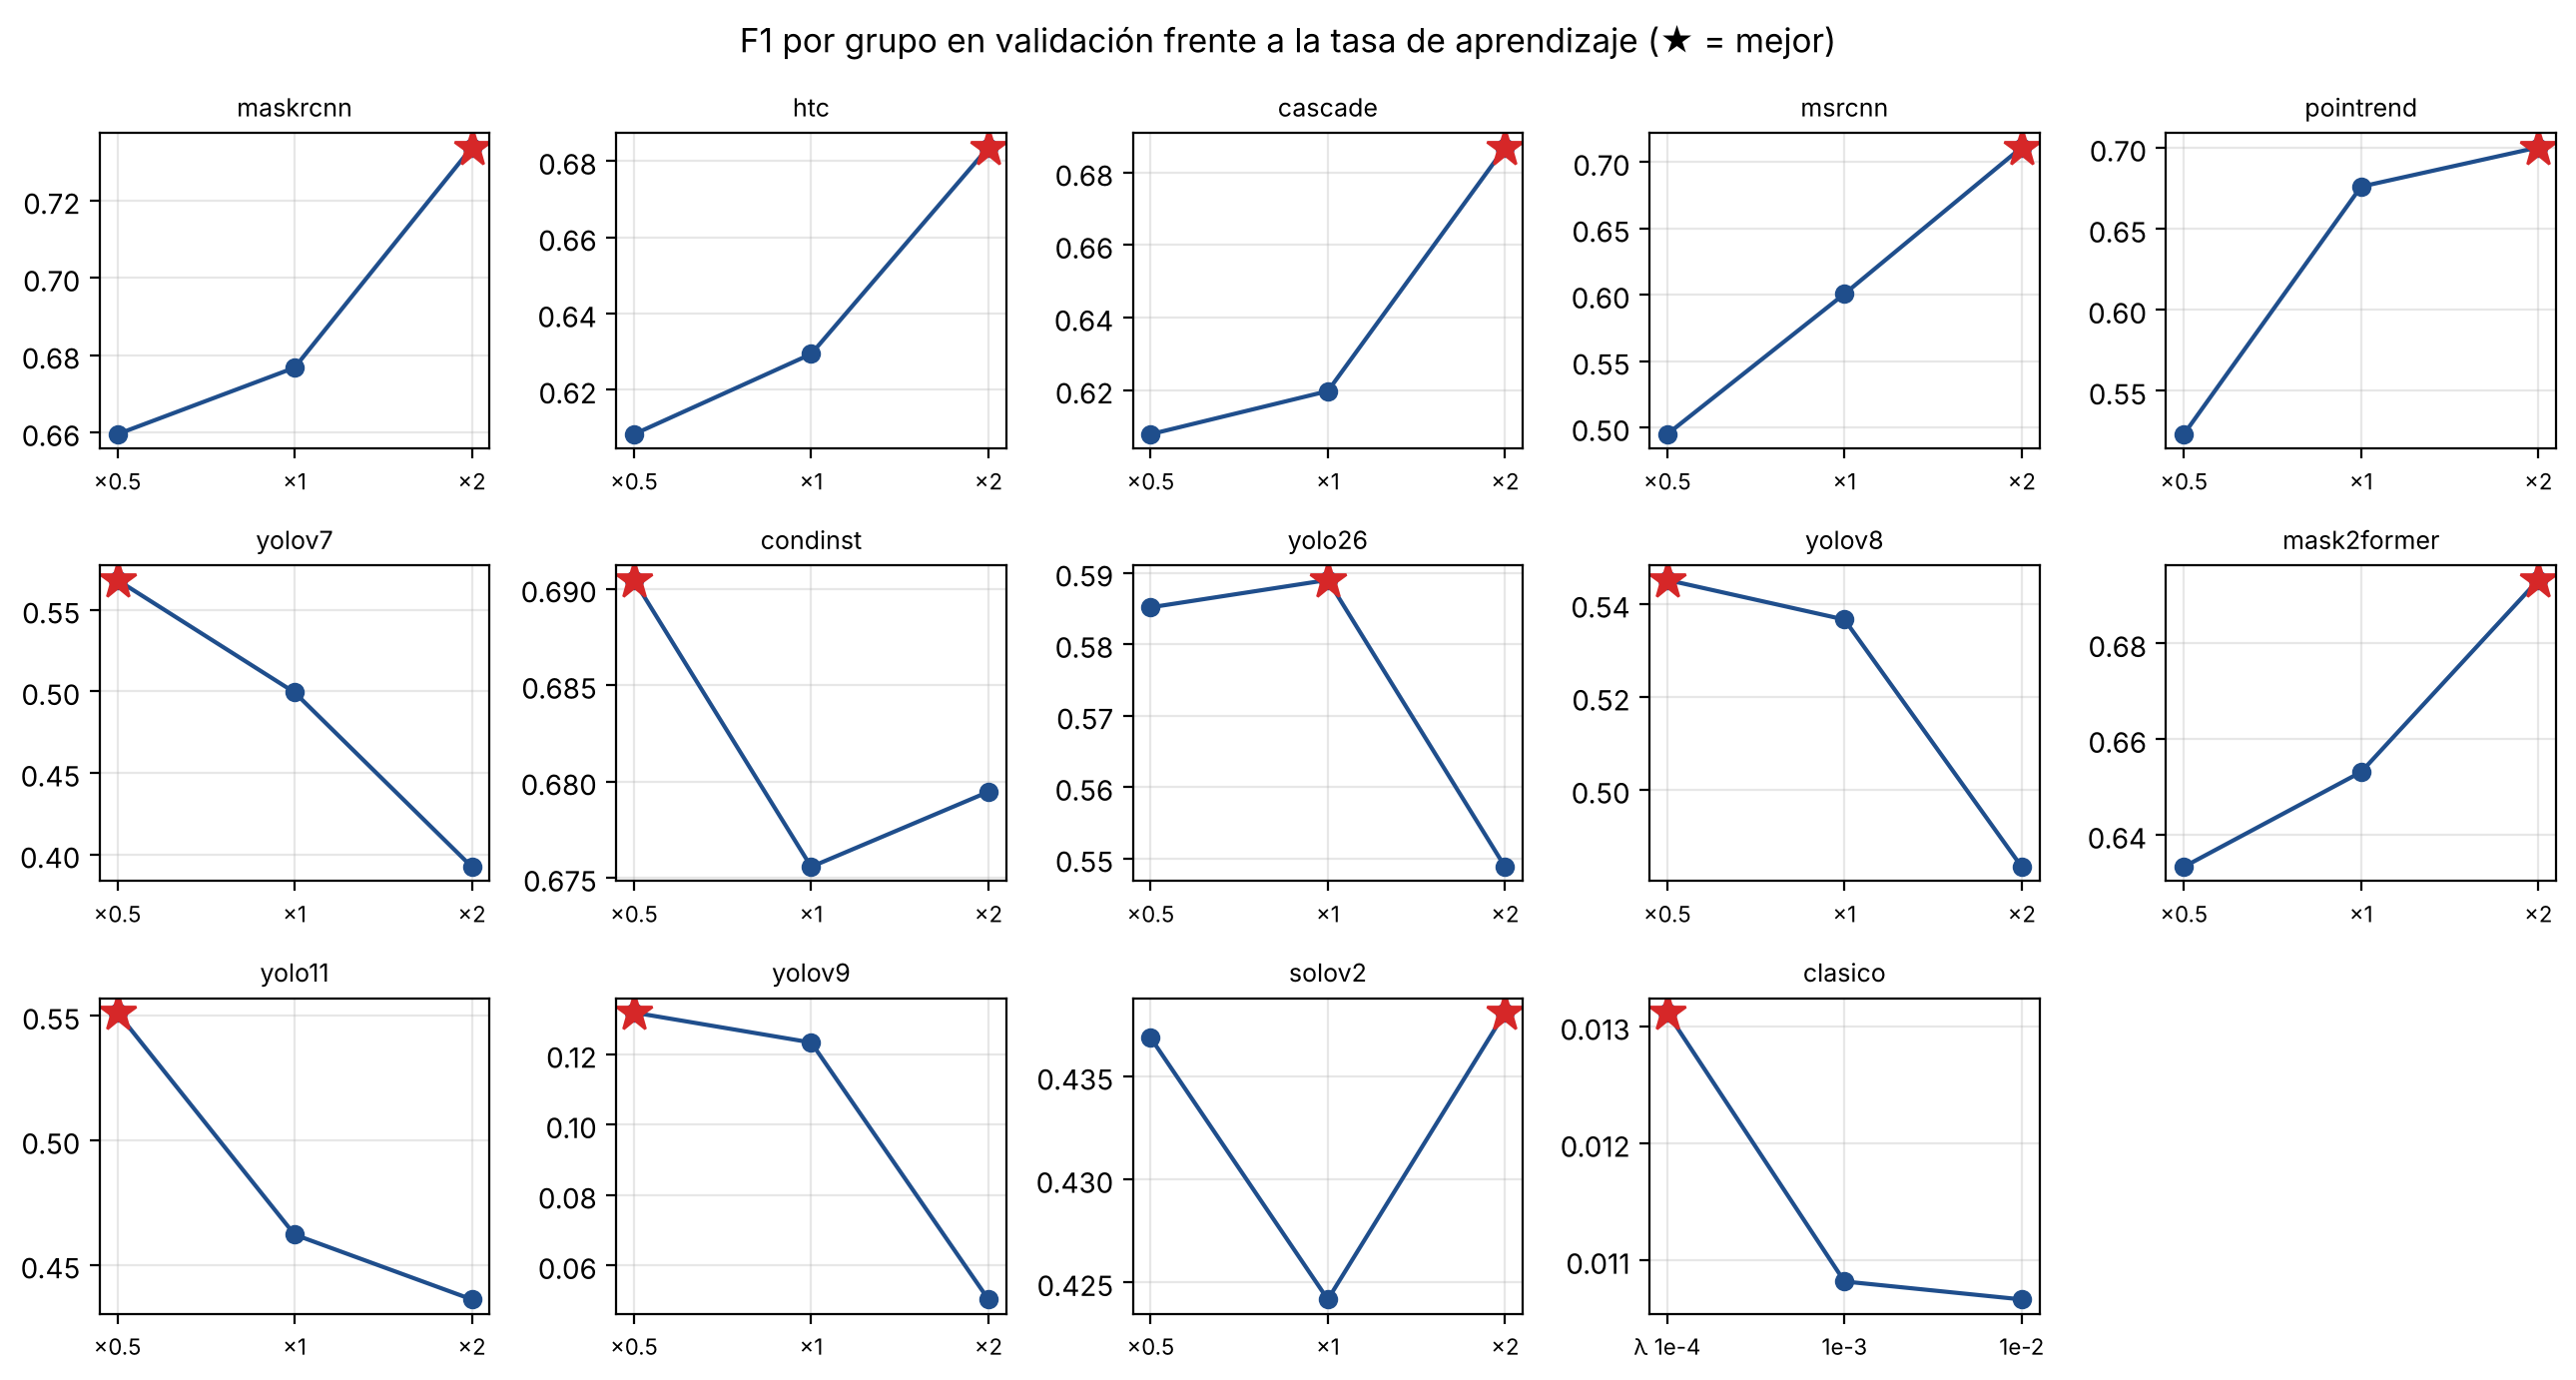

In [3]:
import math
fig, axs = plt.subplots(3, 5, figsize=(13, 7))
for ax, m in zip(axs.ravel(), ORDEN):
    g = b[b.modelo == m].sort_values("valor")
    ax.plot(range(3), g.val_F1_grupo, "o-", color="#1f4e8c")
    i = int(np.argmax(g.val_F1_grupo.values)); ax.plot(i, g.val_F1_grupo.values[i], "*", ms=14, color="#d62728")
    ax.set_xticks(range(3)); ax.set_xticklabels(["λ 1e-4", "1e-3", "1e-2"] if m == "clasico" else ["×0.5", "×1", "×2"], fontsize=8)
    ax.set_title(m, fontsize=9); ax.grid(alpha=.3)
for ax in axs.ravel()[len(ORDEN):]: ax.axis("off")
fig.suptitle("F1 por grupo en validación frente a la tasa de aprendizaje (★ = mejor)"); fig.tight_layout(); plt.show()

**Figura 3.1.** Curva de F1 por grupo en validación contra la tasa de aprendizaje, por modelo (semilla 42, 2 épocas; el eje horizontal es logarítmico: ×0.5, ×1, ×2).

## 3.2.2 Configuración final, costo y memoria

**Tabla 3.2.** Configuración final (lote efectivo, tasa, optimizador) y costo medio por corrida en la RTX 3060 Laptop de 6 GB: minutos de entrenamiento, segundos de predicción por imagen (promedio sobre las 294 imágenes de val, test y `train93`, **medido durante la corrida: incluye cargar datos y calcular máscaras, no es una prueba de latencia aislada**) y pico de memoria de GPU reservada.

In [4]:
rows = []
for m in ORDEN:
    rs = [v for k, v in res.items() if k.startswith(m + "_s")]
    r0 = rs[0]
    lote = "—" if r0["lote"] is None else f'{r0["lote"] * (r0["acumulacion"] or 1)}'
    rows.append({"modelo": m, "optimizador": r0["optimizador"], "lote efectivo": lote,
                 "tasa inicial": r0["lr_inicial"] if r0["lr_inicial"] is not None else r0.get("lambda"),
                 "épocas": r0["epocas"], "parámetros (M)": round((r0["parametros"] or 0) / 1e6, 6),
                 "min entrenar": round(np.mean([x["t_entrenar_s"] for x in rs]) / 60, 1),
                 "s predicción / imagen": round(np.mean([x["t_predecir_s"] / x["n_pred_imagenes"] for x in rs]), 3),
                 "pico GPU reservada (GB)": round(np.nanmean([x.get("gpu_pico_reservada_gb") or np.nan for x in rs]), 2) if any(x.get("gpu_pico_reservada_gb") for x in rs) else "—",
                 "corridas con desborde de VRAM": int(sum(bool(x.get("desborde_vram")) for x in rs))})
display(pd.DataFrame(rows))

,modelo,optimizador,lote efectivo,tasa inicial,épocas,parámetros (M),min entrenar,s predicción / imagen,pico GPU reservada (GB),corridas con desborde de VRAM
0,maskrcnn,SGD,2,0.010000,6,43.922395,17.1,0.162,4.49,0
1,htc,SGD,2,0.005000,6,77.152356,25.9,0.290,5.43,0
2,cascade,SGD,2,0.005000,6,77.020772,22.3,0.169,5.41,0
3,msrcnn,SGD,2,0.005000,6,60.230487,17.0,0.137,5.45,0
4,pointrend,SGD,2,0.005000,6,55.754888,16.6,0.151,5.29,0
5,yolov7,SGD,2,0.005000,6,37.866092,23.3,0.269,—,0
6,condinst,SGD,2,0.000625,6,33.982204,16.7,0.186,3.12,0
7,yolo26,AdamW,2,0.002000,6,3.082751,7.7,0.062,2.8,0
8,yolov8,AdamW,2,0.001000,6,3.390771,4.3,0.055,1.58,0
9,mask2former,AdamW,2,0.000200,6,44.003074,45.8,0.374,5.64,0


**Lectura.** Mask2Former es el más caro (cerca de 46 min por corrida) y los YOLO nano los más baratos. La última columna cuenta las corridas en que Windows desbordó la memoria de GPU a la RAM, lo que enlentece sin dar error; el código topa la memoria de GPU al 95 % para que desborde fallara en vez de continuar (ver Protocolo).

## 3.2.3 Entornos y hardware

Todas las corridas finales y la búsqueda se hicieron en **una sola máquina**: portátil con RTX 3060 Laptop de 6 GB, Windows 10. Cada marco corre en su propio entorno de Python 3.11.18; las versiones exactas salen del `resumen.json` de cada corrida y los `requirements_wdsd_*_congelado.txt`.

In [5]:
ents = {}
for k, v in res.items():
    e = v["entorno"]; ents.setdefault((e["torch"], e.get("torchvision"), e.get("numpy"), e.get("mmdet"), e.get("mmcv"), e.get("mmengine"), e.get("ultralytics")), set()).add(v["modelo"])
pd.DataFrame([{"modelos": ", ".join(sorted(ms)), "torch": k[0], "torchvision": k[1], "numpy": k[2], "mmdet": k[3], "mmcv": k[4], "mmengine": k[5], "ultralytics": k[6]}
              for k, ms in ents.items()]).fillna("—")

,modelos,torch,torchvision,numpy,mmdet,mmcv,mmengine,ultralytics
0,"cascade, condinst, htc, mask2former, msrcnn, p...",2.1.2+cu121,0.16.2+cu121,1.26.4,3.3.0,2.1.0,0.10.4,—
1,"clasico, maskrcnn, vacio, yolo11, yolo26, yolov8",2.11.0+cu128,0.26.0+cu128,2.4.6,—,—,—,8.4.207


**Tabla 3.3.** Versiones registradas en los `resumen.json`. Hay dos conjuntos: torchvision y ultralytics (torch 2.11) y MMDetection (torch 2.1.2). **Aviso:** YOLOv7 y YOLOv9 corrieron con sus repositorios oficiales (entorno `wdsd_yolo9`), pero su `resumen.json` registra las versiones del entorno de MMDetection, incluido `mmdet`; el registro automático parece haber capturado el entorno equivocado (inferido). Para esos dos modelos la fuente fiable es `requirements_wdsd_yolo9_congelado.txt`. Los pesos de GPU del pico de memoria de esos dos tampoco se registran en el resumen (el proceso padre no abre CUDA). Entre entornos cambian el estado de números aleatorios y los kernels de GPU, de modo que la comparación entre marcos no es bit a bit; el determinismo de cada corrida no se verificó.

## 3.2.4 Qué se examinó (enunciado §9.3)

In [6]:
met_cols = [x for x in c.columns if x.startswith(("val_", "test_", "train93_"))]
tabla = pd.DataFrame({
    "elemento": ["Modelos entrenados (Top 10 + 3 base + clásico)", "Modelo trivial (máscara vacía)", "Configuraciones de búsqueda (14 modelos × 3)", "Corridas finales (14 modelos × 5 semillas)",
                 "Métricas registradas por corrida (columnas de val, test y train93)", "Contrastes confirmatorios (RQ1: 10; RQ2: 1)", "Comparaciones exploratorias (todos los pares, 14 modelos)", "Corridas descartadas o repetidas por fallo técnico"],
    "cantidad": [14, 1, int(len(b)), int(len(c[c.modelo != "vacio"])), len(met_cols), 11, 91, "0 (sin fallos registrados)"]})
tabla

,elemento,cantidad
0,Modelos entrenados (Top 10 + 3 base + clásico),14
1,Modelo trivial (máscara vacía),1
2,Configuraciones de búsqueda (14 modelos × 3),42
3,Corridas finales (14 modelos × 5 semillas),70
4,Métricas registradas por corrida (columnas de ...,20
5,Contrastes confirmatorios (RQ1: 10; RQ2: 1),11
6,"Comparaciones exploratorias (todos los pares, ...",91
7,Corridas descartadas o repetidas por fallo téc...,0 (sin fallos registrados)


**Tabla 3.4.** Conteo de todo lo examinado. Las corridas descartadas: ninguna; no apareció `fallo.json` en ninguna carpeta de corrida (observado al cerrar el entrenamiento).

## 3.2.5 Desviaciones respecto al preregistro

Lo siguiente se **comprobó** contra `busqueda.csv`, `corridas.csv` y los `resumen.json`:

- **Épocas y semillas:** las 70 corridas finales usan 6 épocas y las semillas 42 a 46, como dice el preregistro (E = 6, R = 5). La máscara vacía se corrió una vez (no tiene aleatoriedad).
- **Búsqueda:** 42 corridas (14 × 3), semilla 42, 2 épocas, regla de selección aplicada sin discrepancias (Tabla 3.1).
- **Hardware:** el preregistro admitía repartir la semilla 46 en una segunda máquina (RTX 3050); finalmente **todo corrió en la RTX 3060**, que es la opción de menor riesgo para la comparabilidad de tiempos. Los tiempos por modelo son comparables entre sí.
- **Reservas** (QueryInst, SCNet): no se usaron, porque ningún modelo falló técnicamente en las 5 semillas.

Lo siguiente **no se comprobó** aquí y no debe darse por cumplido: que ninguna configuración haya salido de lo declarado en los archivos de configuración de cada marco (se respalda con `ENTRENAMIENTO_E2.md` y la prueba de humo, pero no se auditó corrida por corrida), y el determinismo bit a bit.